In [1]:
from photutils.segmentation import SourceCatalog, deblend_sources, detect_sources, detect_threshold
from astropy.io import fits
from matplotlib import pyplot as plt
import numpy as np
from astropy.visualization import ZScaleInterval
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from astropy.table import Table

In [18]:
#Abrimos los datos de los fits
img_b = fits.open('Img_B.fits')[0].data
img_v = fits.open('Img_V.fits')[0].data
hdr_b = fits.open('Img_B.fits')[0].header
hdr_v = fits.open('Img_V.fits')[0].header
hdr_b

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 4096                                                  
NAXIS2  =                 4096                                                  
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
OBSERVER= 'Cortes, Martinez, Soto' / SBIGFITSEXT The name of the observer       
ORIGIN  = 'MAS500  '           / Description of location                        
TELESCOP= 'MAS500  '           / SBIGFITSEXT The model Telescope                
FOCALLEN=                6500. / SBIGFITSEXT Telescope focal length in mm       
APTDIA  =                 500. / SBIGFITSEXT Aperture diameter in mm            
SBUUID  = '{fac0fa44-d970-46

In [87]:
# Threshold para detectar fuentes
threshold_b = detect_threshold(img_b, n_sigma=3)
threshold_v = detect_threshold(img_v, n_sigma=3)

# Detectamos fuentes
sour_b = detect_sources(img_b, threshold_b, n_pixels=20000)
sour_v = detect_sources(img_v, threshold_v, n_pixels=20000)

print(sour_b)
print(sour_v)

<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
n_labels: 1
labels: [1]
<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
n_labels: 2
labels: [1 2]


In [88]:
galaxy_b = SourceCatalog(img_b, sour_b)
galaxy_v = SourceCatalog(img_v, sour_v)
galaxy_b_table = galaxy_b.to_table()
galaxy_v_table = galaxy_v.to_table()

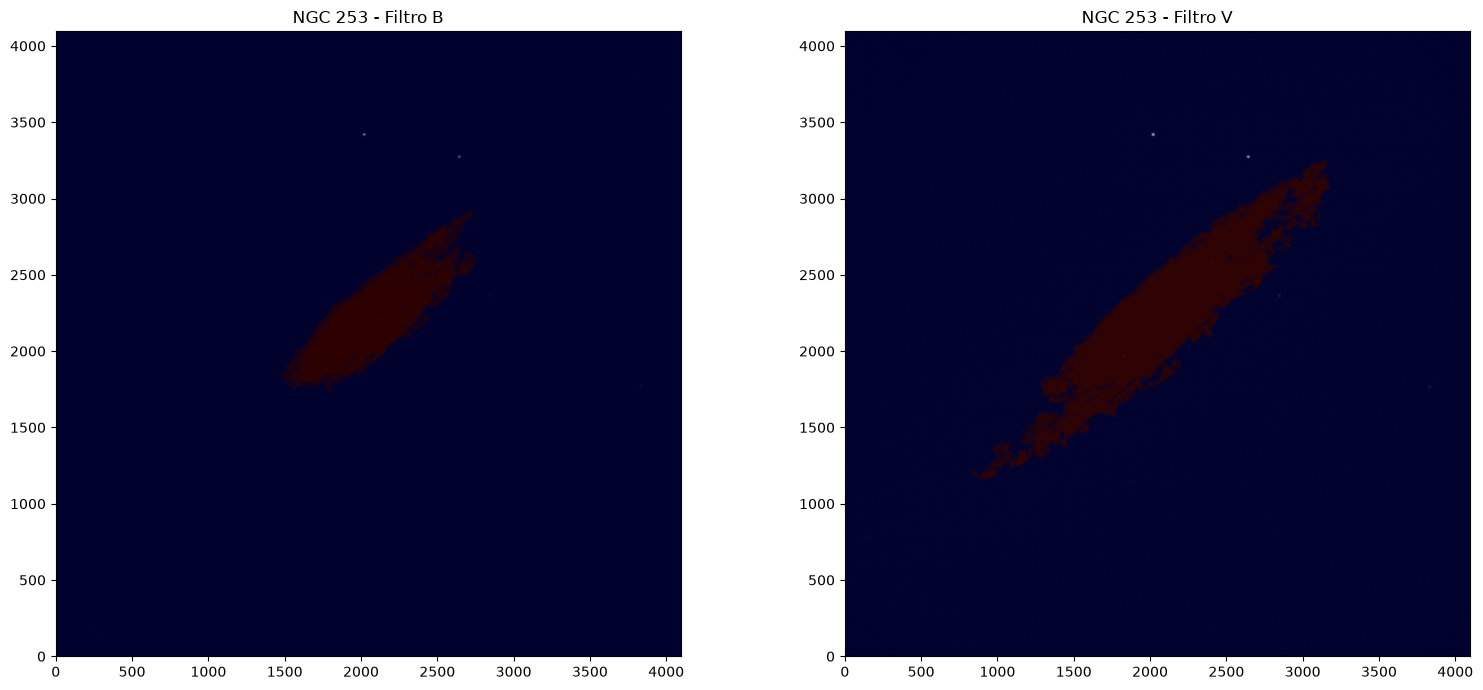

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(16, 7))

# Filtro B
ax[0].imshow(img_b, cmap='gray', origin='lower')
if sour_b is not None:
    ax[0].imshow(sour_b.data, cmap='jet', origin='lower', alpha=0.35)
ax[0].set_title('NGC 253 - Filtro B')

# Filtro V
ax[1].imshow(img_v, cmap='gray', origin='lower')
if sour_v is not None:
    ax[1].imshow(sour_v.data, cmap='jet', origin='lower', alpha=0.35)
ax[1].set_title('NGC 253 - Filtro V')

plt.tight_layout()
plt.show()

In [56]:
img_b_mask= np.zeros_like(img_b)
img_v_mask = np.zeros_like(img_v)

img_b_mask[sour_b.data == 1] = 1
img_v_mask[sour_v.data == 1] = 1


In [64]:
sour_b_masked = detect_sources(img_b, threshold_b, n_pixels=50, mask = img_b_mask.astype(bool))
sour_v_masked = detect_sources(img_v, threshold_v, n_pixels=50, mask = img_v_mask.astype(bool))

In [65]:
sour_b_masked

<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
n_labels: 130
labels: [  1   2   3   4   5 ... 126 127 128 129 130]

In [68]:
#Separamos fuentes
deblend_b = deblend_sources(img_b, sour_b_masked, n_pixels=50, nlevels=10, contrast=0.05)
deblend_v = deblend_sources(img_v, sour_v_masked, n_pixels=50, nlevels=10, contrast=0.05)
#npixels tamaño mínimo para considerar una subregión significativa.
#contrast evita dividir la nebulosa en demasiados trozos.
#nlevels uficiente resolución sin fragmentar el gas difuso.
print(deblend_b, deblend_v)

<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
n_labels: 131
labels: [  1   2   3   4   5 ... 127 128 129 130 131] <photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
n_labels: 201
labels: [  1   2   3   4   5 ... 197 198 199 200 201]


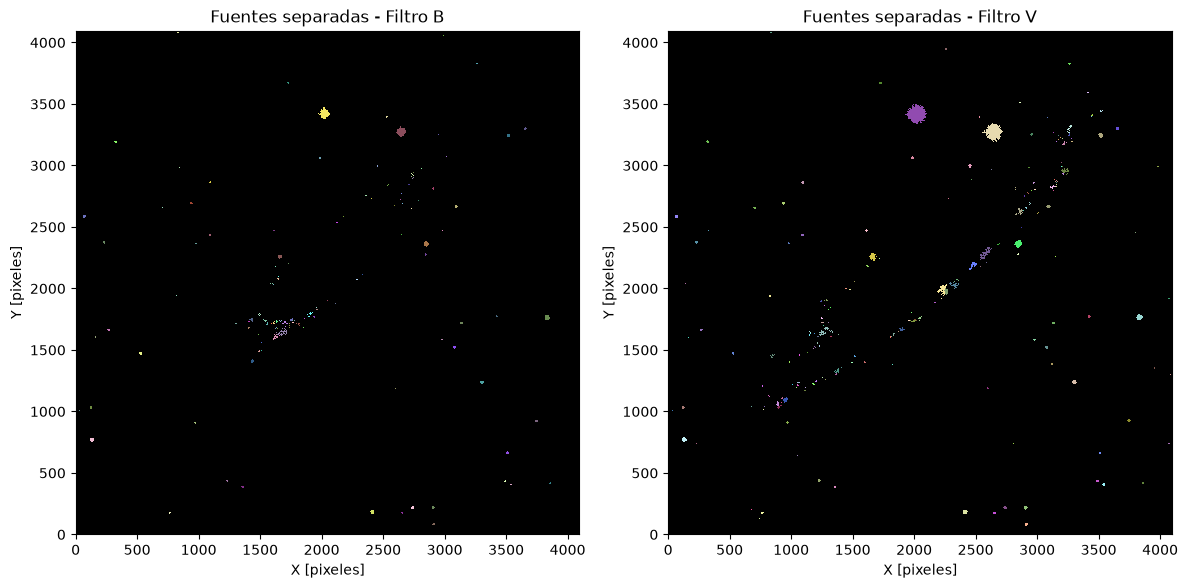

In [69]:
# Creamos los mapas de colores
cmap_deblend_b = deblend_b.make_cmap(seed=123)
cmap_deblend_v = deblend_v.make_cmap(seed=123)

# Visualizamos las fuentes separadas
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Filtro B
ax[0].imshow(
    deblend_b.data,
    origin='lower',
    cmap=cmap_deblend_b,
    interpolation='nearest'
)
ax[0].set_title('Fuentes separadas - Filtro B')
ax[0].set_xlabel('X [pixeles]')
ax[0].set_ylabel('Y [pixeles]')

# Filtro V
ax[1].imshow(
    deblend_v.data,
    origin='lower',
    cmap=cmap_deblend_v,
    interpolation='nearest'
)
ax[1].set_title('Fuentes separadas - Filtro V')
ax[1].set_xlabel('X [pixeles]')
ax[1].set_ylabel('Y [pixeles]')

plt.tight_layout()
plt.show()

In [71]:
#Catalogo
cat_b = SourceCatalog(img_b, deblend_b)
cat_v = SourceCatalog(img_v, deblend_v)
tbl_b = cat_b.to_table()
tbl_v = cat_b.to_table()
print(tbl_b)
print(tbl_v)

label     x_centroid         y_centroid     sky_centroid ... segment_flux_err     kron_flux      kron_flux_err flags 
                                                         ...                                                         
----- ------------------ ------------------ ------------ ... ---------------- ------------------ ------------- ------
    1 2911.6406728699326  83.50823239995036         None ...              nan  141806.0922295888           nan      0
    2   969.858854464346  90.49615197269983         None ...              nan  27110.92571769201           nan      0
    3  2414.065187930708 182.97999706249948         None ...              nan  258943.4338752832           nan      0
    4  765.8104967186983 175.48011766296844         None ...              nan  105251.2350308508           nan      0
    5  2654.895930296213  175.7969831810902         None ...              nan   86440.1785355874           nan      0
    6   2741.23606432942 217.62174970437846         None

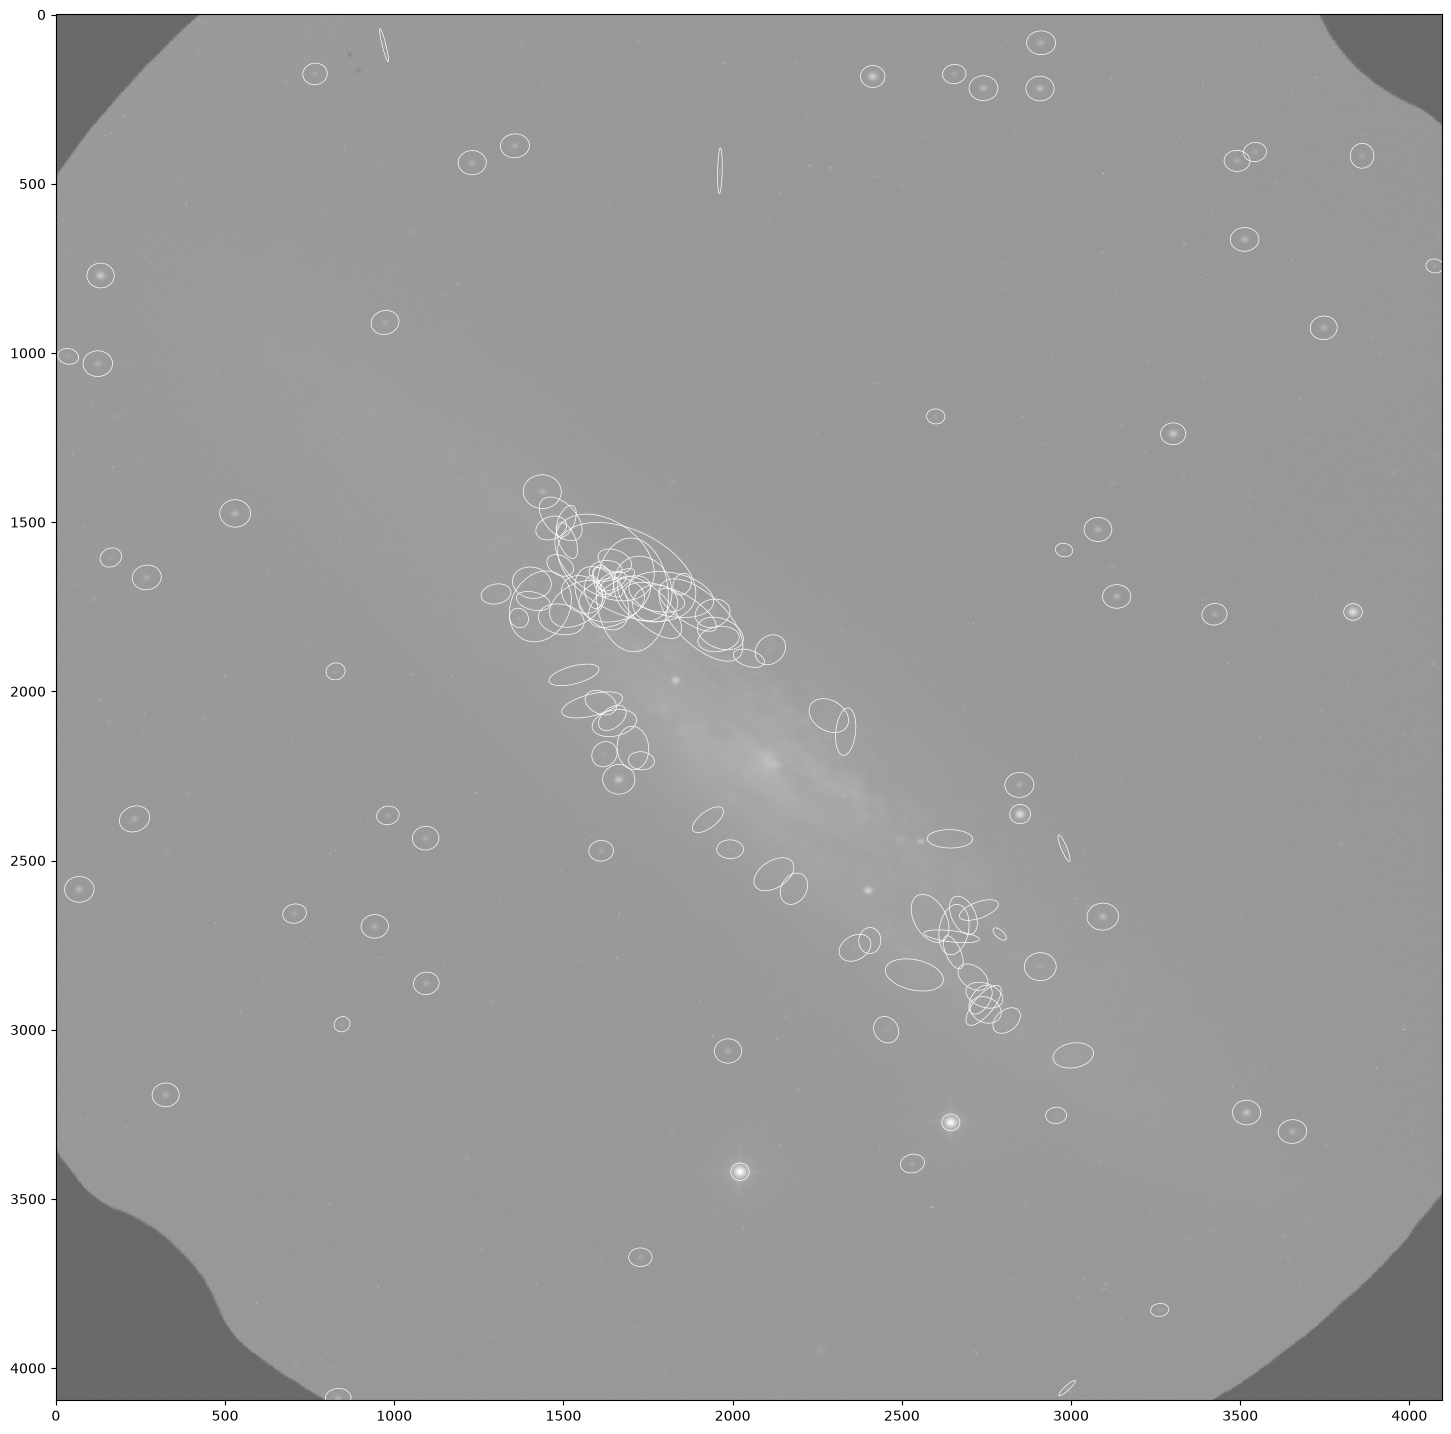

In [72]:
fig = plt.figure(figsize = (18, 18))
ax = plt.axes()
ax.imshow(np.log10(np.abs(img_b + 1.)), cmap = "gray")
cat_b.plot_kron_apertures(ax = ax, color = "white", lw = 0.5);

In [73]:
#Tablas
tabla_b = cat_b.to_table()['label','xcentroid','ycentroid','area','segment_flux']
tabla_v = cat_v.to_table()['label','xcentroid','ycentroid','area','segment_flux']

#Printeo las tablas con los datos
print(tabla_b, tabla_v)

label     x_centroid         y_centroid      area     segment_flux   
                                             pix2                    
----- ------------------ ------------------ ------ ------------------
    1 2911.6406728699326  83.50823239995036  334.0  26236.37413406372
    2   969.858854464346  90.49615197269983   50.0  4942.116401672363
    3  2414.065187930708 182.97999706249948  895.0  179198.5375404358
    4  765.8104967186983 175.48011766296844  177.0  9721.076606750488
    5  2654.895930296213  175.7969831810902  154.0   8716.88924407959
    6   2741.23606432942 217.62174970437846  435.0  41657.65964508057
    7  2908.297155645817  218.6024472697534  498.0  55037.09135055542
    8 1356.4960494924853   387.907416013534  290.0 20479.419929504395
    9  3543.590133931298 406.21741869993565  157.0   8881.44856262207
   10  3860.141131915797 417.34064522526177  189.0 11653.103923797607
   11 3490.6415829229104 432.44267673004015  226.0 14487.381534576416
   12  1230.28536532

In [74]:
#Flujo real
tabla_b['segment_flux'] = tabla_b['segment_flux']/hdr_b['EXPTIME']
tabla_v['segment_flux'] = tabla_v['segment_flux']/hdr_v['EXPTIME']

print(tabla_b, tabla_v)

label     x_centroid         y_centroid      area     segment_flux   
                                             pix2                    
----- ------------------ ------------------ ------ ------------------
    1 2911.6406728699326  83.50823239995036  334.0 109.31822555859884
    2   969.858854464346  90.49615197269983   50.0  20.59215167363485
    3  2414.065187930708 182.97999706249948  895.0  746.6605730851492
    4  765.8104967186983 175.48011766296844  177.0  40.50448586146037
    5  2654.895930296213  175.7969831810902  154.0 36.320371850331625
    6   2741.23606432942 217.62174970437846  435.0 173.57358185450235
    7  2908.297155645817  218.6024472697534  498.0 229.32121396064758
    8 1356.4960494924853   387.907416013534  290.0  85.33091637293498
    9  3543.590133931298 406.21741869993565  157.0  37.00603567759196
   10  3860.141131915797 417.34064522526177  189.0  48.55459968249003
   11 3490.6415829229104 432.44267673004015  226.0  60.36408972740173
   12  1230.28536532

In [75]:
#Magnitudes con los zeropoint de la calibracion
zp_b = 19.94171587
zp_v = 18.68188450
tabla_b['magnitude'] = zp_b - 2.5 * np.log(tabla_b['segment_flux'])
tabla_v['magnitude'] = zp_v - 2.5 * np.log(tabla_v['segment_flux'])
print(tabla_b, tabla_v)

label     x_centroid         y_centroid      area     segment_flux        magnitude     
                                             pix2                                       
----- ------------------ ------------------ ------ ------------------ ------------------
    1 2911.6406728699326  83.50823239995036  334.0 109.31822555859884  8.206058046745738
    2   969.858854464346  90.49615197269983   50.0  20.59215167363485 12.379440828787743
    3  2414.065187930708 182.97999706249948  895.0  746.6605730851492 3.4026891322475024
    4  765.8104967186983 175.48011766296844  177.0  40.50448586146037 10.688184045024494
    5  2654.895930296213  175.7969831810902  154.0 36.320371850331625 10.960768890373483
    6   2741.23606432942 217.62174970437846  435.0 173.57358185450235  7.050211839028778
    7  2908.297155645817  218.6024472697534  498.0 229.32121396064758 6.3539066155824955
    8 1356.4960494924853   387.907416013534  290.0  85.33091637293498  8.825373790860851
    9  3543.590133931

In [76]:
print(f"{np.sort(tabla_b['magnitude'])}")
print(f"{np.sort(tabla_v['magnitude'])}")

    magnitude     
------------------
-5.049694995822826
-4.178086345327102
0.6568476508991914
0.9817368549007774
3.4026891322475024
 3.899759009840732
3.9279793483390897
 4.411381406607841
 5.103219749862523
 5.698968889671386
 6.295867878468885
6.3539066155824955
 6.900645756506696
               ...
 14.02638316593546
 14.03534674822647
14.042006149131245
14.052274432888513
14.061349395975846
14.121030303641247
14.154081732070853
 14.16056848139303
14.180309000351087
14.182179610719931
14.209540819478486
 14.23006951275311
 14.23741186912646
Length = 131 rows
     magnitude      
--------------------
  -9.821333836232355
  -9.239458039713913
  -4.544404066596734
  -4.184803645322862
 -1.7201059868205348
 -1.1895301311039326
 -1.0234734430823913
 -0.8361238854071047
-0.13102273787856333
  1.1269386510890946
   1.901244672889007
   2.411398466750562
  2.4509272430363858
                 ...
  12.289689035208935
   12.32875835902497
   12.36093406433994
  12.416300426364904
  12.432901

In [90]:
# Limitar a 250 fuentes para facilitar la visualización del diagrama color-magnitud
n = min(len(tabla_v), len(tabla_b))
B_V = tabla_b['magnitude'][:n] - tabla_v['magnitude'][:n]

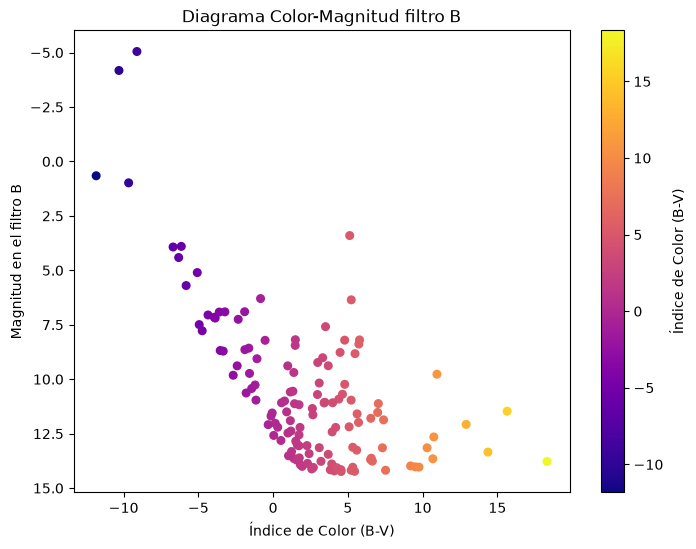

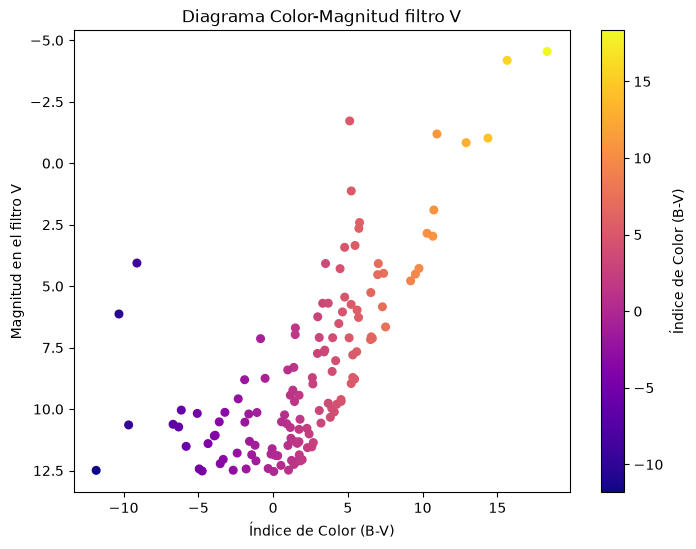

In [91]:
# Crear el diagrama color-magnitud
plt.figure(figsize=(8, 6))
plt.scatter(B_V, tabla_b['magnitude'][:n], c=B_V, cmap='plasma', s = 30)
plt.colorbar(label="Índice de Color (B-V)")
plt.gca().invert_yaxis()  # Invertir el eje y para que las magnitudes más brillantes estén arriba

# Añadir etiquetas
plt.xlabel("Índice de Color (B-V)")
plt.ylabel("Magnitud en el filtro B")
plt.title("Diagrama Color-Magnitud filtro B")

plt.show()

# Crear el diagrama color-magnitud
plt.figure(figsize=(8, 6))
plt.scatter(B_V, tabla_v['magnitude'][:n], c=B_V, cmap='plasma', s = 30)
plt.colorbar(label="Índice de Color (B-V)")
plt.gca().invert_yaxis()  # Invertir el eje y para que las magnitudes más brillantes estén arriba

# Añadir etiquetas
plt.xlabel("Índice de Color (B-V)")
plt.ylabel("Magnitud en el filtro V")
plt.title("Diagrama Color-Magnitud filtro V")

plt.show()